# H01 — Your first waveform

**Part III · the laboratory that follows lectures 4 and 5: tasks 1 to 3 in class, tasks 4 and 5 on your own**

> **References**
>
> (Misner et al. 1973), (Schutz 2022), (Blanchet 2024)

## From a formula to a signal

This laboratory starts from two results of lecture 4, both from the quadrupole
formula applied to a binary. The first is the amplitude of an inspiral,

$$
h = \frac{4}{r}\left(\frac{G\mathcal{M}}{c^{2}}\right)^{5/3}
\left(\frac{\pi f}{c}\right)^{2/3},
$$

> **The symbols**
>
> - **$h$** — the strain amplitude
> - **$r$** — the distance to the source
> - **$\mathcal{M}$** — the chirp mass, $(m_{1}m_{2})^{3/5}/(m_{1}+m_{2})^{1/5}$: the only combination of the two masses the amplitude depends on
> - **$f$** — the frequency of the wave, twice the orbital frequency

The second is that the orbit decays because the system radiates. Put those
together and the frequency is no longer a constant: it rises, the amplitude
rises with it and the signal is a **chirp**.

This laboratory builds that chirp. Then it does the thing that makes the
formula useful — it goes backwards, recovering the chirp mass from the
frequency evolution alone, which is what a real parameter estimation does with
more care and more parameters.

Everything runs offline.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys, os

# the course root holds gwcourse_palette.py; find it from wherever we are
here = os.path.abspath('.')
while not os.path.exists(os.path.join(here, 'gwcourse_palette.py')):
    here = os.path.dirname(here)
sys.path.insert(0, here)

from gwcourse_palette import P, apply_style
apply_style()

G    = 6.67430e-11        # m^3 kg^-1 s^-2
C    = 2.99792458e8       # m s^-1
MSUN = 1.98892e30         # kg
MPC  = 3.0857e22          # m


def chirp_mass(m1, m2):
    """Chirp mass from the two component masses, in the same units."""
    return (m1 * m2) ** 0.6 / (m1 + m2) ** 0.2


# GW150914 as the detector sees it: the source masses 36 and 29 solar masses,
# stretched by the redshift, 1 + z = 1.09
M1_GW150914, M2_GW150914 = 39.2, 31.6   # solar masses
MC_GW150914 = chirp_mass(M1_GW150914 * MSUN, M2_GW150914 * MSUN)
print(f"chirp mass: {MC_GW150914 / MSUN:.1f} solar masses")


chirp mass: 30.6 solar masses


> **Try these before you read the answers**
>
> Each task is a step of the construction and they build on each other. Write
> the code, look at what comes out, then compare.


## 1. How long until it merges

Energy loss makes the orbit shrink, so the frequency rises. Integrating the
quadrupole result gives the time left before merger when the wave frequency is
$f$:

$$
\tau(f) = \frac{5}{256\,\pi^{8/3}}
\left(\frac{G\mathcal{M}}{c^{3}}\right)^{-5/3} f^{-8/3} .
$$

> **The symbols**
>
> - **$\tau$** — the time remaining before merger
> - **$f$** — the wave frequency at that moment

Write it as a function and evaluate it for GW150914 at 20, 35, 100 and 150 Hz,
with the masses the detector sees, 39.2 and 31.6 solar masses.

**What to look for.** The steepness. The exponent is $-8/3$, so the last
octave takes a small fraction of the time the first one did — which is why a
detector needs to be sensitive at low frequency to see a long signal and why
the loudest part is the shortest.


In [11]:
# your code here
def  time_merge(MC,f):
    """Compute the time before merger (s), for a given chirp mass (kg) and frequency (s^-1)"""
    return (5 / (256 * np.pi**(8/3))) * (G * MC/ C**3)**(-5/3)* f**(-8/3)

for f0 in (20.0, 35.0, 100.0, 150.0):
    print(f"{f0:6.0f} Hz -> {time_merge(MC_GW150914,  f0):7.3f} s to merger")


    20 Hz ->   0.733 s to merger
    35 Hz ->   0.165 s to merger
   100 Hz ->   0.010 s to merger
   150 Hz ->   0.003 s to merger


In [7]:
#Prof Solution
def time_to_merger(f, mc):
    """Seconds from wave frequency f to merger, for chirp mass mc (kg)."""
    return (5 / (256 * np.pi ** (8 / 3))) * (G * mc / C ** 3) ** (-5 / 3) * f ** (-8 / 3)


for f0 in (20.0, 35.0, 100.0, 150.0):
    print(f"{f0:6.0f} Hz -> {time_to_merger(f0, MC_GW150914):7.3f} s to merger")

    20 Hz ->   0.733 s to merger
    35 Hz ->   0.165 s to merger
   100 Hz ->   0.010 s to merger
   150 Hz ->   0.003 s to merger


<details>
<summary>Solution</summary>

```python
def time_to_merger(f, mc):
    """Seconds from wave frequency f to merger, for chirp mass mc (kg)."""
    return (5 / (256 * np.pi ** (8 / 3))) * (G * mc / C ** 3) ** (-5 / 3) * f ** (-8 / 3)


for f0 in (20.0, 35.0, 100.0, 150.0):
    print(f"{f0:6.0f} Hz -> {time_to_merger(f0, MC_GW150914):7.3f} s to merger")

</details>
`0.733`, `0.165`, `0.010` and `0.003` seconds. The whole visible signal of
GW150914 above 20 Hz lasts under a second and the last 100 Hz of the sweep
take ten milliseconds. A neutron star binary, with a chirp mass twenty
times smaller, stays in band for minutes instead.
```


## 2. The frequency evolution

Invert $\tau(f)$ to get the frequency as a function of time. With $\tau$ the
time remaining,

$$
f(\tau) = \frac{1}{\pi}
\left(\frac{5}{256\,\tau}\right)^{3/8}
\left(\frac{G\mathcal{M}}{c^{3}}\right)^{-5/8} .
$$

Build a time array at 4096 Hz starting where $f = 20\,\mathrm{Hz}$ and stopping
5 ms before merger and plot the frequency against time.

**What to look for.** A curve that is almost flat for most of its length and
then turns up sharply. Say where half the time is spent.


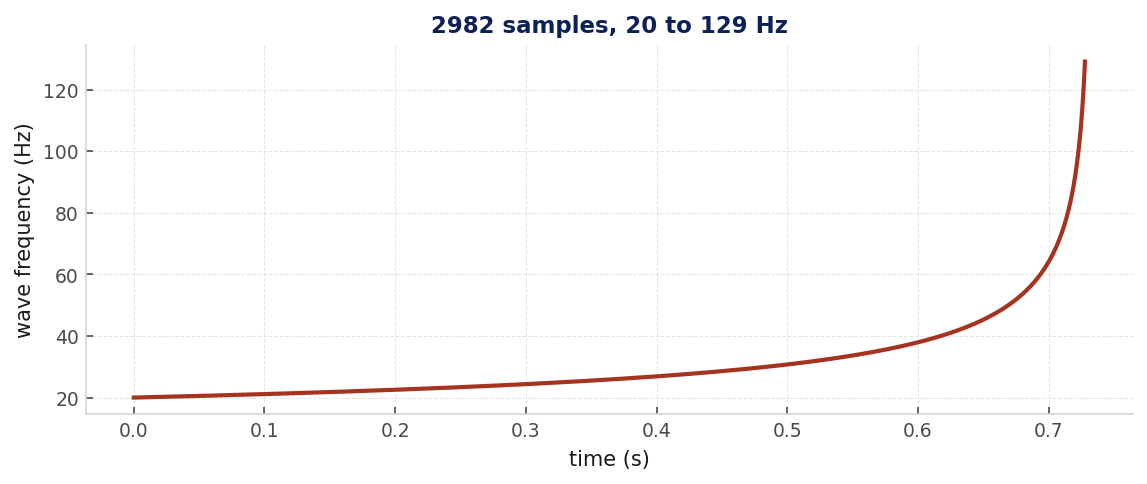

the frequency doubles after 0.617 s of 0.728


In [15]:
# your code here
def f_tau(t, MC):
    return (1/np.pi) * (5/(256 * t))**(3/8) * (G*MC/(C**3))**(-5/8)

fs = 4096.0
t = np.arange(0.0, time_merge(MC_GW150914, 20) - 0.005, 1/fs)
tau = time_merge(MC_GW150914, 20) - t
f = f_tau(tau, MC_GW150914)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(t, f, color=P['BRICK'], lw=2)
ax.set_xlabel('time (s)')
ax.set_ylabel('wave frequency (Hz)')
ax.set_title(f'{len(t)} samples, {f[0]:.0f} to {f[-1]:.0f} Hz')
plt.show()

half = t[np.argmin(np.abs(f - 2 * f[0]))]
print(f"the frequency doubles after {half:.3f} s of {t[-1]:.3f}")

<details>
<summary>Solution</summary>

```python
def frequency(tau, mc):
    """Wave frequency in Hz, tau seconds before merger."""
    return (1 / np.pi) * (5 / (256 * tau)) ** (3 / 8) * (G * mc / C ** 3) ** (-5 / 8)


fs = 4096.0
tau0 = time_to_merger(20.0, MC_GW150914)
t = np.arange(0.0, tau0 - 0.005, 1 / fs)
tau = tau0 - t
f = frequency(tau, MC_GW150914)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(t, f, color=P['BRICK'], lw=2)
ax.set_xlabel('time (s)')
ax.set_ylabel('wave frequency (Hz)')
ax.set_title(f'{len(t)} samples, {f[0]:.0f} to {f[-1]:.0f} Hz')
plt.show()

half = t[np.argmin(np.abs(f - 2 * f[0]))]
print(f"the frequency doubles after {half:.3f} s of {t[-1]:.3f}")

</details>
The frequency doubles after about three quarters of a second out of eight
tenths, so most of the time in band is spent in the first octave. That is the
shape of every inspiral and it is why searches integrate for a long time at low
amplitude rather than waiting for the loud part.
```


## 3. Build the waveform

Now assemble $h(t)$: the amplitude above and a phase that comes from
**integrating** the frequency.

$$
h(t) = \frac{4}{r}\left(\frac{G\mathcal{M}}{c^{2}}\right)^{5/3}
\left(\frac{\pi f(t)}{c}\right)^{2/3}\cos\Phi(t),
\qquad
\Phi(t) = 2\pi\!\int^{t} f(t')\,\mathrm{d} t' .
$$

> **The symbols**
>
> - **$\Phi(t)$** — the phase accumulated up to time $t$, which is why the frequency is integrated rather than simply evaluated

Take $r = 410\,\mathrm{Mpc}$. Plot the whole signal and then the last tenth of
a second.

> **Careful — The mistake to avoid**
>
> The phase is $2\pi\int f\,\mathrm{d} t$, not $2\pi f t$. The second is only correct
> when $f$ is constant and here it is precisely not — using it gives a signal
> that looks plausible and has the wrong number of cycles, which is the kind of
> error a plot will not show you and a matched filter will.
>
> `np.cumsum(f) / fs` is the integral you need.

> **Careful — What a wrong phase costs**
>
> A wrong phase gives the wrong number of cycles. A model that drifts by half
> a cycle from the signal is out of step with it: compared cycle by cycle, the
> two cancel where they should add. A search built on that model would miss the
> signal or fit it with the wrong chirp mass. Task 4 shows the second: the
> chirp mass is read from the phase, so an error in the phase goes straight
> into the mass.


In [ ]:
# your code here
r = 410 * MPC

h_0 = (4/r) * (G*MC_GW150914/C**2)**(5/3) * (np.pi * f/C)**(2/3)
Phi = 2*np.pi * np.cumsum(f)/fs

h = h_0 * np.cos(Phi)

<details>
<summary>Solution</summary>

```python
distance = 410 * MPC

amplitude = (4 / distance) * (G * MC_GW150914 / C ** 2) ** (5 / 3) \
    * (np.pi * f / C) ** (2 / 3)
phase = 2 * np.pi * np.cumsum(f) / fs
h = amplitude * np.cos(phase)

fig, axes = plt.subplots(2, 1, figsize=(10, 5))
axes[0].plot(t, h, color=P['BLUE'], lw=0.8)
axes[0].set_ylabel('strain')
axes[0].set_title('the whole inspiral')

late = t > t[-1] - 0.1
axes[1].plot(t[late], h[late], color=P['BLUE'], lw=1.4)
axes[1].set_xlabel('time (s)')
axes[1].set_ylabel('strain')
axes[1].set_title('the last tenth of a second')
fig.tight_layout()
plt.show()

print(f"peak |h| = {np.abs(h).max():.2e}")

</details>
`1.95e-21` and the second panel is the shape everybody recognises: amplitude
and frequency rising together. Note that the two are not independent — both are
driven by the same energy loss, which is why a chirp carries so much
information in so few cycles.
```


## 4. Recover the chirp mass

Now go backwards. Suppose you were handed the frequency track and nothing
else. Rearranging $\tau(f)$ shows that

$$
f^{-8/3} = \frac{256\,\pi^{8/3}}{5}
\left(\frac{G\mathcal{M}}{c^{3}}\right)^{5/3}\,\tau ,
$$

so $f^{-8/3}$ is a **straight line** in time and its slope contains the chirp
mass and nothing else.

Fit a straight line to $f^{-8/3}$ against $t$ with `np.polyfit` and get
$\mathcal{M}$ back out of the slope.

**What to look for.** Agreement with the value you put in, to the precision of
the fit. Then say why this is the quantity that gets measured well.


In [ ]:
# your code here


<details>
<summary>Solution</summary>

```python
y = f ** (-8 / 3)
slope, intercept = np.polyfit(t, y, 1)

# tau = tau0 - t, so d(f^-8/3)/dt = -(256 pi^{8/3}/5)(G Mc/c^3)^{5/3}
mc_recovered = (C ** 3 / G) * (5 / (256 * np.pi ** (8 / 3)) * (-slope)) ** (3 / 5)

print(f"recovered {mc_recovered / MSUN:.2f} solar masses")
print(f"put in    {MC_GW150914 / MSUN:.2f} solar masses")

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t, y, color=P['BRICK'], lw=2, label='$f^{-8/3}$')
ax.plot(t, slope * t + intercept, color=P['INK'], lw=1.2, ls='--', label='fit')
ax.set_xlabel('time (s)'); ax.set_ylabel('$f^{-8/3}$')
ax.legend()
plt.show()

</details>
`30.60` against `30.60`: exact, because the data were generated by the same
model being fitted. That is not a result, it is a check that the algebra is
right — and it is the step people skip before running the same code on data
where the answer is unknown.

The physics is in the straight line. The frequency evolution of an inspiral
depends, at leading order, on **one** combination of the masses, so that
combination is what a measurement determines precisely. Separating $m_{1}$ from
$m_{2}$ needs the higher order terms in the phase and they are much smaller.
```


## 5. Against a real waveform model

Your waveform is Newtonian: it knows about energy loss at leading order and
nothing else. The models used in the analysis go further and `IMRPhenomD` is
one of them. Its name says what it is. **IMR**: it covers the inspiral, the
merger and the ringdown as one waveform. **Phenom**: it is a phenomenological
fit, written in the frequency domain. Its inspiral part is the post-Newtonian
series with a few extra terms tuned on numerical relativity and its merger and
ringdown parts are fitted to numerical relativity simulations. **D**: the
version for spins aligned with the orbital axis, with the quadrupole mode
only.

Generate `IMRPhenomD` for the same system with `pycbc` and overlay the two.

**What to look for.** Where they agree and where they part company and
whether the peak amplitudes are close.


In [ ]:
# your code here


<details>
<summary>Solution</summary>

```python
from pycbc.waveform import get_td_waveform

hp, _ = get_td_waveform(approximant='IMRPhenomD',
                        mass1=M1_GW150914, mass2=M2_GW150914,
                        delta_t=1 / fs, f_lower=20.0,
                        distance=410)
t_ref = hp.sample_times.numpy()          # merger sits at t = 0
h_ref = hp.numpy()

# put ours on the same clock: our last sample is 5 ms before merger
t_ours = t - t[-1] - 0.005

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t_ref, h_ref, color=P['GREY_MID'], lw=1.0, label='IMRPhenomD')
ax.plot(t_ours, h, color=P['BRICK'], lw=1.0, label='ours, Newtonian')
ax.set_xlim(-0.5, 0.05)
ax.set_xlabel('time from merger (s)')
ax.set_ylabel('strain')
ax.legend()
plt.show()

print(f"peak ours        {np.abs(h).max():.2e}")
print(f"peak IMRPhenomD  {np.abs(h_ref).max():.2e}")

</details>
The peak amplitudes agree to two per cent — `1.95e-21` against `1.99e-21` —
which is a genuine success for a formula that assumed slow motion and a weak
field.

The phases do not stay together. Early on the two are indistinguishable; in
the last cycles ours drifts, because the post-Newtonian corrections grow as the
orbital speed approaches $c$. And ours simply stops where the model continues
into the merger and the ringdown, which is exactly the stretch numerical
relativity was needed for.

That is the honest summary of the quadrupole formula: right about how loud, how
long and at what frequency; wrong about the last few cycles, which is where
most of the signal to noise ratio lives. Part III is about closing that gap.
```


## 6. How long is each signal in band?

Yesterday's lecture ended on the time a binary has left once its wave is at
the frequency $f$:

$$
\tau(f) = \frac{5}{256\,\pi^{8/3}}
\left(\frac{G\mathcal{M}}{c^{3}}\right)^{-5/3} f^{-8/3} .
$$

That time is how long the signal stays in band from $f$ onwards. Take four
pairs, two with equal masses and two without:

| pair | $m_{1} + m_{2}$ |
|---|---|
| two neutron stars | $1.4 + 1.4\,M_{\odot}$ |
| two heavy black holes | $30 + 30\,M_{\odot}$ |
| a neutron star and a black hole | $1.4 + 10\,M_{\odot}$ |
| two unequal black holes | $10 + 50\,M_{\odot}$ |

For each pair compute $\mu$, $\eta$ and $\mathcal{M}$, then the time in band
from 20 Hz and from 30 Hz, with the function of task 1. Print a table.

**What to look for.** Which of the three mass numbers the time depends on
and how steeply. Then compare the two columns: the ratio should be the same
on every row. Say why.


In [ ]:
# your code here


<details>
<summary>Solution</summary>

```python
systems = [(1.4, 1.4), (30.0, 30.0), (1.4, 10.0), (10.0, 50.0)]

print('pair          mu      eta   chirp mass   from 20 Hz   from 30 Hz   ratio')
for m1, m2 in systems:
    M, mu = m1 + m2, m1 * m2 / (m1 + m2)
    eta, mc = mu / M, chirp_mass(m1, m2)
    tau20 = time_to_merger(20.0, mc * MSUN)
    tau30 = time_to_merger(30.0, mc * MSUN)
    print(f'{m1:4g} + {m2:4g}   {mu:6.2f}   {eta:.3f}   {mc:8.2f}   '
          f'{tau20:9.3f} s   {tau30:8.3f} s   {tau30 / tau20:.3f}')
print(f'(3/2)^(-8/3) = {(3 / 2) ** (-8 / 3):.3f}')

</details>
| pair | $\mu$ | $\eta$ | $\mathcal{M}$ | from 20 Hz | from 30 Hz |
|---|---|---|---|---|---|
| $1.4 + 1.4$ | 0.70 | 0.250 | 1.22 | 158 s | 54 s |
| $30 + 30$ | 15.0 | 0.250 | 26.1 | 0.96 s | 0.32 s |
| $1.4 + 10$ | 1.23 | 0.108 | 2.99 | 35 s | 12 s |
| $10 + 50$ | 8.33 | 0.139 | 18.4 | 1.7 s | 0.58 s |

The time depends on the masses only through the chirp mass, as
$\mathcal{M}^{-5/3}$: twenty times the chirp mass, a signal a hundred and
sixty times shorter. From 30 Hz every time is 0.34 of the time from 20 Hz,
on every row, because $\tau \propto f^{-8/3}$ and $(3/2)^{-8/3} = 0.34$. The
ten hertz between 20 and 30 Hz hold two thirds of the signal: that is the
steepness of the sweep.
```


## 7. Four binaries, one formula

Now see the four signals themselves. Write a function that builds the Newtonian chirp of any pair at 410 Mpc, from
20 Hz up to the innermost stable orbit, $f_{\mathrm{isco}} = c^{3}/(6^{3/2}\pi GM)$,
where the inspiral ends. Plot the last quarter of a second of each one, four
panels. Write $\mu$, $\eta$, $\mathcal{M}$ and the time left from 20 Hz and
from 30 Hz in a box on each panel: how long each signal stays in band.

> **The symbols**
>
> - **$f_{\mathrm{isco}}$** — the wave frequency at the innermost stable circular orbit, where the inspiral ends and the Newtonian formulas stop
> - **$M$** — the total mass $m_{1} + m_{2}$

**What to look for.** Which number sets the amplitude, which the duration and
which the frequency at which the signal ends. Two pairs have the same total
mass and different $\eta$: compare them.


In [ ]:
# your code here


<details>
<summary>Solution</summary>

```python
def newtonian_chirp(m1, m2, f_low=20.0, fs=fs, distance=distance):
    """Time, frequency and strain of the Newtonian chirp of (m1, m2) solar
    masses at `distance`, from f_low up to the innermost stable orbit."""
    M = (m1 + m2) * MSUN
    mc = chirp_mass(m1 * MSUN, m2 * MSUN)
    f_isco = C ** 3 / (6 ** 1.5 * np.pi * G * M)
    tau_low, tau_isco = time_to_merger(f_low, mc), time_to_merger(f_isco, mc)
    t = np.arange(0.0, tau_low - tau_isco, 1 / fs)      # t = 0 at f_low
    tau = tau_low - t                                    # time left
    f = frequency(tau, mc)
    amplitude = (4 / distance) * (G * mc / C ** 2) ** (5 / 3) * (np.pi * f / C) ** (2 / 3)
    phase = 2 * np.pi * np.cumsum(f) / fs
    return t, f, amplitude * np.cos(phase), f_isco


fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, (m1, m2) in zip(axes.flat, systems):
    t, f, h, f_isco = newtonian_chirp(m1, m2)
    M, mu = m1 + m2, m1 * m2 / (m1 + m2)
    eta, mc = mu / M, chirp_mass(m1, m2)
    tau20 = time_to_merger(20.0, mc * MSUN)
    tau30 = time_to_merger(30.0, mc * MSUN)
    late = t > t[-1] - 0.25
    ax.plot(t[late] - t[-1], h[late], color=P['BLUE'], lw=0.9)
    ax.set_title(f'{m1:g} + {m2:g} solar masses')
    ax.text(0.03, 0.95,
            f'$\\mu$ = {mu:.2f}   $\\eta$ = {eta:.3f}\n'
            f'$\\mathcal{{M}}$ = {mc:.2f}\n'
            f'$\\tau$(20 Hz) = {tau20:.3g} s   $\\tau$(30 Hz) = {tau30:.3g} s',
            transform=ax.transAxes, va='top',
            bbox=dict(boxstyle='round', fc='white', ec=P['GREY_LIGHT']))
    ax.set_xlabel('time to the last stable orbit (s)')
    ax.set_ylabel('strain')
    print(f'{m1:5.1f} + {m2:5.1f}:  mu {mu:6.2f}  eta {eta:.3f}  '
          f'chirp mass {mc:6.2f}  from 20 Hz {tau20:8.3f} s  from 30 Hz {tau30:7.3f} s  ends at {f_isco:7.1f} Hz  '
          f'peak {np.abs(h).max():.2e}')
fig.tight_layout()
plt.show()

</details>
| pair | $\mu$ | $\eta$ | $\mathcal{M}$ | from 20 Hz | from 30 Hz | ends at | peak strain |
|---|---|---|---|---|---|---|---|
| $1.4 + 1.4$ | 0.70 | 0.250 | 1.22 | 158 s | 54 s | 1570 Hz | $4.7\times10^{-23}$ |
| $30 + 30$ | 15.0 | 0.250 | 26.1 | 0.96 s | 0.32 s | 73 Hz | $1.2\times10^{-21}$ |
| $1.4 + 10$ | 1.23 | 0.108 | 2.99 | 35 s | 12 s | 386 Hz | $9.4\times10^{-23}$ |
| $10 + 50$ | 8.33 | 0.139 | 18.4 | 1.7 s | 0.58 s | 73 Hz | $6.4\times10^{-22}$ |

From 30 Hz every time is a third of the time from 20 Hz, because
$\tau \propto f^{-8/3}$ and $(3/2)^{-8/3} = 0.34$: the ten hertz between 20
and 30 Hz hold two thirds of the signal.

The chirp mass sets the amplitude and the duration: the heavier the chirp
mass, the louder and the shorter the signal. The total mass sets where the
signal ends, because $f_{\mathrm{isco}}$ goes as $1/M$: the two $60\,M_{\odot}$
pairs both stop at 73 Hz, in the middle of the band, while the two neutron
stars run up to 1.5 kHz. Between those two pairs only $\eta$ differs. Through
it the chirp mass differs too: the unequal pair is quieter and lasts longer.
```


## 8. All four, laid on top of each other

Plot the last half second of the four signals on one axis, with the end of
each inspiral at $t = 0$.

**What to look for.** How different four signals from one formula can be. The
heaviest pair is the loudest and the slowest; the two neutron stars are a thin
fast line. A search must look for all of them at once.


In [ ]:
# your code here


<details>
<summary>Solution</summary>

```python
colours = [P['BLUE'], P['BRICK'], P['SAGE_DARK'], P['AMBER_DARK']]

fig, ax = plt.subplots(figsize=(12, 4.2))
for (m1, m2), colour in zip(systems, colours):
    t, f, h, f_isco = newtonian_chirp(m1, m2)
    late = t > t[-1] - 0.5
    ax.plot(t[late] - t[-1], h[late], color=colour, lw=0.9, label=f'{m1:g} + {m2:g}')
ax.set_xlabel('time to the last stable orbit (s)')
ax.set_ylabel('strain')
ax.legend(loc='upper left')
plt.show()

</details>
The two $60\,M_{\odot}$ pairs dominate the plot: a few slow cycles, the equal
pair twice as loud as the unequal one. The neutron star pair is barely
visible on this scale, a line twenty times thinner, with many more cycles in
the same half second. Same formula, four signals that look nothing alike. A
search cannot look for one shape: it has to cover the whole family.
```


## 9. Where they sit against the detectors

The last question is whether a detector would see them. Compare each signal
with the noise of the detectors, frequency by frequency.

Take the Fourier transform of each signal, $\tilde{h}(f)$, with `np.fft.rfft`
and plot its **characteristic strain** $2f\,|\tilde{h}(f)|$ between 20 Hz and
$f_{\mathrm{isco}}$. On the same axes plot the sensitivity of LIGO and Virgo
in the fourth observing run, $\sqrt{f\,S_{n}(f)}$, from the two files in
`labs/data/sensitivity/`, which hold $\sqrt{S_{n}(f)}$ against $f$. Use
logarithmic axes.

> **The symbols**
>
> - **$\tilde{h}(f)$** — the Fourier transform of the strain; `np.fft.rfft(h) / fs` gives it with the right units
> - **$2f\,|\tilde{h}(f)|$** — the characteristic strain: the strain the signal accumulates in a band of width $f$ around $f$, dimensionless
> - **$S_{n}(f)$** — the noise power spectral density of a detector; $\sqrt{f\,S_{n}(f)}$ is the noise on the same dimensionless scale

Both curves are dimensionless. Where the signal's curve lies above the noise,
the detector gains more from the signal than it loses to the noise, so the
height of the signal above the noise, read across the band, is what makes a
detection.

**What to look for.** Which part of the band each pair occupies and where it
rises above the noise. The signal starts abruptly at 20 Hz; smooth the first
five per cent of it with a half cosine before the transform. Otherwise the
sharp start leaks into every frequency.


In [ ]:
# your code here


<details>
<summary>Solution</summary>

```python
sens_dir = os.path.join(here, 'labs', 'data', 'sensitivity')
ligo = np.loadtxt(os.path.join(sens_dir, 'aligo_O4.txt'))
virgo = np.loadtxt(os.path.join(sens_dir, 'avirgo_O4.txt'))

fig, ax = plt.subplots(figsize=(10, 6))
ax.loglog(ligo[:, 0], ligo[:, 1] * np.sqrt(ligo[:, 0]), color=P['BLUE'], lw=2.0, label='LIGO, O4')
ax.loglog(virgo[:, 0], virgo[:, 1] * np.sqrt(virgo[:, 0]), color=P['BRICK'], lw=2.0, label='Virgo, O4')
for (m1, m2), colour in zip(systems, colours):
    t, f, h, f_isco = newtonian_chirp(m1, m2)
    n = len(h)
    window = np.ones(n)
    ramp = int(0.05 * n)                                   # a smooth start
    window[:ramp] = 0.5 * (1 - np.cos(np.pi * np.arange(ramp) / ramp))
    h_f = np.fft.rfft(h * window) / fs
    ff = np.fft.rfftfreq(n, 1 / fs)
    band = (ff >= 20) & (ff <= f_isco)
    ax.loglog(ff[band], 2 * ff[band] * np.abs(h_f[band]), color=colour, lw=1.4, ls='--',
              label=f'{m1:g} + {m2:g}, 410 Mpc')
ax.set_xlim(10, 3000)
ax.set_ylim(1e-24, 1e-20)
ax.set_xlabel('frequency (Hz)')
ax.set_ylabel(r'$2f\,|\tilde{h}(f)|$  and  $\sqrt{f\,S_n(f)}$')
ax.legend(loc='upper right')
plt.show()

</details>
The two $60\,M_{\odot}$ pairs sit between 20 and 73 Hz, in the low part of
the band, well above the noise at 410 Mpc. The neutron star pair runs from
20 Hz to 1.5 kHz and crosses the noise near 1 kHz, so most of what a detector
gains from it comes below a few hundred hertz. The $1.4 + 10$ pair is in
between. The heavy pairs are loud and short; the light pair is quiet, long
and spread over the band. That is why the first detection was a pair of
heavy black holes and why a neutron star pair must be close to be seen.
```


## What to hand in

A notebook that runs from top to bottom and contains:

- the four times to merger of task 1;
- the frequency track and the waveform, both plotted and labelled;
- the recovered chirp mass beside the one you put in;
- the overlay against `IMRPhenomD` and a paragraph on where the two part
  company and why;
- the table of the four pairs, their waveforms, their overlay and the figure
  against the detectors,
  with a paragraph on which pair a detector sees best and why.

> **Where this goes next**
>
> You now have a waveform generator. In `H09` it becomes a **template**: the
> same signal, correlated against real detector noise, is how a search finds
> something that no plot would ever show. The chirp mass fit you did by hand
> here becomes a likelihood over several parameters in `H10`.
>
> Every one of those steps needs what you built today: a model of the signal you
> are looking for.


## Software

`numpy` for the waveform and `pycbc.waveform.get_td_waveform` for the
`IMRPhenomD` model you compared against (Khan et al. 2016). The quadrupole
result being tested is (Misner et al. 1973) and the post-Newtonian corrections
that explain the disagreement are reviewed in (Blanchet 2024).

**References**

- Misner et al. (1973). *Gravitation*.
- Schutz (2022). *A First Course in General Relativity*.
- Blanchet (2024). *Post-Newtonian theory for gravitational waves*.
- Khan et al. (2016). *Frequency-domain gravitational waves from nonprecessing black-hole binaries. II. A phenomenological model for the advanced detector era*.
